**Partes**
- **A. Pronóstico (hold-out horario de 168 h):** los modelos comparados entre
  sí, con métricas RMSE y MAE:

## Glosario de datos

Los nombres técnicos de las columnas se mantienen en el CSV (`blue_sell`,
`brecha_pct`, ...). Su traducción y descripción viven en un único lugar:
`diccionario_datos.py`. La tabla de abajo se genera desde ese diccionario, así
que nunca se desincroniza del código.


## 1. Carga de datos y configuración

El **split temporal** es fijo: `H_TEST = 7`. Todo lo anterior a los últimos 7
días es entrenamiento; los últimos 7 días son test. Se usa el mismo corte
temporal para todos los modelos.

In [1]:
import os
import sys
import warnings
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (accuracy_score, roc_auc_score, roc_curve,
                             confusion_matrix)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 120)

# --- configuración desde modelado/.env (con fallback si no existe) -----------
CWD = Path.cwd()
ENV_FILE = CWD / ".env" if (CWD / ".env").exists() else CWD / "modelado" / ".env"
if ENV_FILE.exists():
    try:
        from dotenv import load_dotenv
        load_dotenv(ENV_FILE, override=False)
        print(f"config: {ENV_FILE.name} cargado")
    except ImportError:
        print("config: python-dotenv no instalado; usando rutas por defecto")

_env_base = Path(os.getenv("MODELADO_DIR", "")) if os.getenv("MODELADO_DIR") else None
BASE = (_env_base.parent if _env_base and _env_base.exists()
        else (CWD.parent if (CWD / "PLAN.md").exists() else CWD))
MODELADO = Path(os.getenv("MODELADO_DIR", BASE / "modelado"))
OUT = Path(os.getenv("OUTPUTS_DIR", MODELADO / "outputs"))
OUT.mkdir(parents=True, exist_ok=True)

H_TEST = int(os.getenv("H_TEST", 168))   # hold-out horario: 7 días × 24 h

serie = pd.read_csv(MODELADO / "serie_diaria_blue.csv",
                    parse_dates=["fecha"]).set_index("fecha")
panel = pd.read_csv(MODELADO / "panel_diario.csv", parse_dates=["fecha_d"])
mkt = pd.read_csv(Path(os.getenv("DATA_DIR", BASE / "data")) / "processed" / "market_hourly.csv",
                  parse_dates=["fecha"])
docs = pd.read_csv(Path(os.getenv("DATA_C_DIR", BASE / "data_c")) / "gaceta" / "docs_etiquetados.csv")
tags = pd.read_csv(Path(os.getenv("DATA_C_DIR", BASE / "data_c")) / "gaceta" / "doc_tags.csv")

print(f"serie diaria   : {len(serie)} días ({serie.index.min().date()} -> {serie.index.max().date()})")
print(f"panel diario   : {len(panel)} días ({panel.fecha_d.min().date()} -> {panel.fecha_d.max().date()})")
print(f"mercado horario: {len(mkt)} filas ({mkt.fecha.min()} -> {mkt.fecha.max()})")
print(f"Gaceta         : {len(docs)} normas, {tags.tag.nunique()} tags")
print(f"hold-out       : H_TEST={H_TEST} h")

# diccionario de datos en español (etiquetas/descripciones para gráficos)
sys.path.insert(0, str(MODELADO))
sys.path.insert(0, str(BASE))
from diccionario_datos import (etiqueta, etiqueta_eje, etiqueta_tag,  # noqa: E402
                               renombrar, tabla_glosario)

config: .env cargado
serie diaria   : 366 días (2025-10-24 -> 2026-10-24)
panel diario   : 179 días (2026-04-29 -> 2026-10-24)
mercado horario: 4318 filas (2026-04-27 02:00:00+00:00 -> 2026-10-24 02:00:00+00:00)
Gaceta         : 509 normas, 9 tags
hold-out       : H_TEST=168 h


In [2]:
# Glosario generado desde diccionario_datos.py, en 2 grupos:
#   1. Modelo     → predictores de la regresión + targets (25 variables)
#   2. Referencia → datos crudos, canales base de la Gaceta y fechas (29)
from diccionario_datos import GRUPO_MODELO, GRUPO_REFERENCIA, tabla_glosario

for g in (GRUPO_MODELO, GRUPO_REFERENCIA):
    print(f"═══ {g} ═══")
    display(tabla_glosario(grupo_filtro=g).set_index("Etiqueta").drop(columns="Grupo"))

═══ 1. Modelo (predictores y targets) ═══


,Variable,Descripción,Unidad,Ejemplo
Etiqueta,,,,
Blue (venta),blue_sell,Precio de venta del dólar paralelo: lo que pag...,Bs/USD,"11,85"
Blue (medio),blue_mid,Precio medio del dólar blue. Es horario: en ca...,Bs/USD,"11,84"
Brecha cambiaria,brecha_pct,Brecha blue vs oficial: (blue / oficial − 1) ×...,%,"1,3 %"
Brecha (rezago 1 d),brecha_lag1,Brecha del día anterior.,%,
Brecha (rezago 2 d),brecha_lag2,Brecha de hace 2 días.,%,
Brecha (rezago 7 d),brecha_lag7,Brecha de hace 7 días.,%,
Brecha a 1 día,brecha_fwd1,Brecha del día siguiente (target h=1).,%,
Brecha a 7 días,brecha_fwd7,Brecha 7 días después (target h=7).,%,
Oficial (rezago 1 d),oficial_lag1,Nivel oficial del día anterior.,Bs/USD,


═══ 2. Referencia (datos crudos y Gaceta) ═══


,Variable,Descripción,Unidad,Ejemplo
Etiqueta,,,,
Blue (compra),blue_buy,Precio de compra del dólar paralelo: a cuánto ...,Bs/USD,"11,83"
Oficial (medio),oficial_mid,Tipo de cambio oficial del BCB. Se publica una...,Bs/USD,"11,69"
Oficial (venta),oficial_sell,Precio de venta del dólar oficial del BCB (pro...,Bs/USD,"6,96"
"Oficial (venta, dato crudo)",official_sell,Precio de venta oficial tal como llega en hist...,Bs/USD,"6,96"
"Oficial (compra, dato crudo)",official_buy,Precio de compra oficial tal como llega en his...,Bs/USD,"6,86"
Retorno diario del blue,ret_blue_pct,Variación porcentual del blue respecto del día...,%,"+0,42 %"
Variación diaria del oficial,d_oficial_pct,Variación porcentual diaria del tipo de cambio...,%,"0,00 %"
Volumen P2P (24 h),vol_media_24h,Volumen negociado en las últimas 24 h en el me...,USD,105 309
Día de la semana,dia_sem,0 = lunes … 6 = domingo.,—,


In [3]:
fin_h = mkt.fecha.max().tz_localize(None)
inicio_h = fin_h - pd.Timedelta(hours=H_TEST - 1)
print(f"hold-out horario: {inicio_h} -> {fin_h} ({H_TEST} h)")

hold-out horario: 2026-10-17 03:00:00 -> 2026-10-24 02:00:00 (168 h)


## 1b. Datos crudos vs datos tras EDA (horario)

El resumen que consumen los modelos es **producto del EDA** — y ahora existen
dos salidas del EDA según el uso: **horaria** (sección 5b) y **diaria**
(secciones 3-4). Esta sección muestra la cadena completa para la semana de
test:

| Etapa | Qué es | Granularidad | La usan |
|---|---|---|---|
| **Crudo** | snapshots event-driven de la API (cada cotización que cambia) | minutos, irregular | nadie directamente |
| **EDA horario** | grilla regular cada hora, huecos interpolados (máx. 3) | 168 h/semana | sección 5b (RL y ARIMA horarios) |

Las métricas de cada sección se calculan sobre **su** nivel de EDA: comparar
un pronóstico horario contra promedios diarios (o viceversa) sería comparar
granularidades distintas.

In [4]:
# ── CRUDO: snapshots event-driven (history_full.csv) ────────────────────────
h_raw = pd.read_csv(Path(os.getenv("DATA_DIR", BASE / "data")) / "history_full.csv")
h_raw["fecha"] = pd.to_datetime(h_raw["timestamp"], unit="s")
h_raw = h_raw[(h_raw["blue_sell"] > 0) & (h_raw["official_sell"] > 0)]
h_raw["brecha_snapshot"] = (h_raw["blue_sell"] / h_raw["official_sell"] - 1) * 100

inicio = serie.index[-H_TEST]
fin = serie.index[-1] + pd.Timedelta(days=1)
crudo_semana = h_raw.loc[(h_raw.fecha >= inicio) & (h_raw.fecha < fin),
                         ["fecha", "blue_sell", "brecha_snapshot"]].copy()
print(f"semana de test: {inicio.date()} -> {fin.date() - pd.Timedelta(days=1)}")
print(f"filas CRUDAS (snapshots event-driven): {len(crudo_semana)}")
display(crudo_semana.head(6).rename(columns={
    "blue_sell": etiqueta("blue_sell"),
    "brecha_snapshot": f"{etiqueta('brecha_pct')} (snapshot)"}))

# ── EDA HORARIO: grilla regular cada hora (la usa la sección 5b) ────────────
hor_eda = (mkt.set_index("fecha").sort_index()[["blue_mid", "brecha_pct"]]
           .asfreq("h"))
hor_eda.index = hor_eda.index.tz_localize(None)   # mismo tz que la serie diaria
n_nan = int(hor_eda["blue_mid"].isna().sum())
hor_eda = hor_eda.interpolate(limit=3)
eda_hora_semana = hor_eda.loc[inicio:fin - pd.Timedelta(hours=1)]
print(f"filas EDA HORARIO (grilla regular): {len(eda_hora_semana)} "
      f"({n_nan} huecos interpolados en todo el período)")
display(eda_hora_semana.rename(columns={
    "blue_mid": etiqueta("blue_mid"),
    "brecha_pct": etiqueta("brecha_pct")}).head(6).round(3))

print(f"cadena de la semana: {len(crudo_semana)} snapshots crudos -> "
      f"{len(eda_hora_semana)} horas (grilla regular)")

semana de test: 2026-05-10 -> 2026-10-24
filas CRUDAS (snapshots event-driven): 15978


,fecha,Blue (venta),Brecha cambiaria (snapshot)
18203,2026-05-10 00:05:12,9.96,43.103448
18204,2026-05-10 00:19:35,9.95,42.959770
18205,2026-05-10 00:35:04,9.94,42.816092
18206,2026-05-10 00:50:32,9.95,42.959770
18207,2026-05-10 01:04:55,9.95,42.959770
18208,2026-05-10 01:20:33,9.95,42.959770


filas EDA HORARIO (grilla regular): 4011 (3 huecos interpolados en todo el período)


,Blue (medio),Brecha cambiaria
fecha,,
2026-05-10 00:00:00,9.930,43.705
2026-05-10 01:00:00,9.932,43.741
2026-05-10 02:00:00,9.940,43.850
2026-05-10 03:00:00,9.941,43.868
2026-05-10 04:00:00,9.939,43.831
2026-05-10 05:00:00,9.940,43.850


cadena de la semana: 15978 snapshots crudos -> 4011 horas (grilla regular)


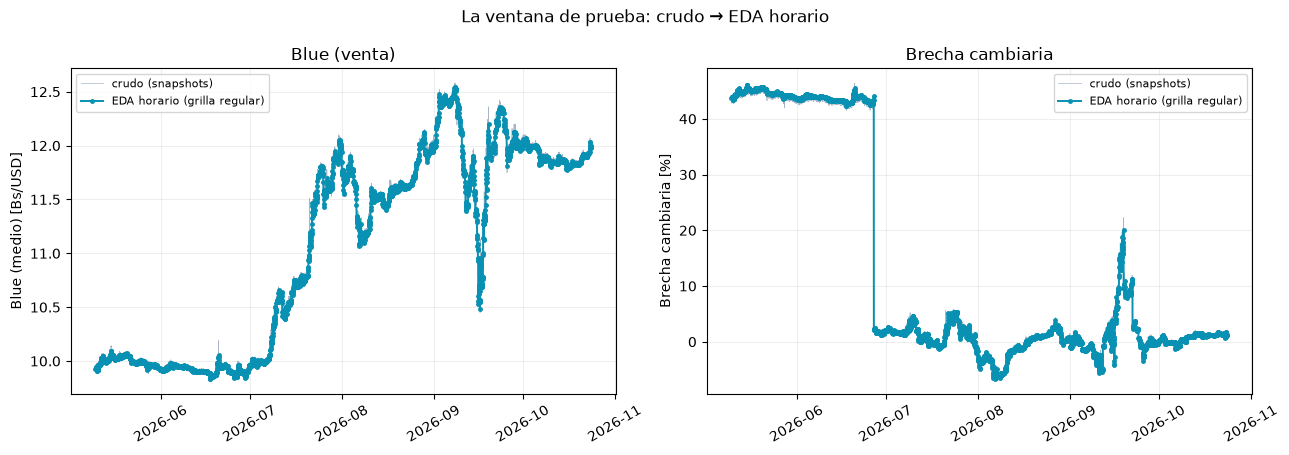

In [5]:
# visual: crudo (snapshots) -> EDA horario (grilla regular), ambos cada hora
from charts import figuras

fig = figuras.raw_vs_eda(crudo_semana, eda_hora_semana,
                         etiqueta=etiqueta, etiqueta_eje=etiqueta_eje)
fig.savefig(OUT / "nb_raw_vs_eda.png", dpi=130, bbox_inches="tight")
plt.show()


## 2. Métricas de evaluación

Para cada modelo se reportan dos métricas de error sobre el hold-out:

- **RMSE** (*Root Mean Squared Error*) — `sqrt(mean(e²))`. Eleva los errores al
  cuadrado antes de promediar, así que **penaliza más los errores grandes**;
  se interpreta en las mismas unidades del target (Bs o %).
- **MAE** (*Mean Absolute Error*) — `mean(|e|)`. Error promedio en valor
  absoluto, más **robusto a valores atípicos** que el RMSE. Si `RMSE ≫ MAE`,
  hubo picos mal pronosticados.

Ambas salen de `sklearn.metrics` (via `metricas.py`).

Además, cada modelo se compara contra el **baseline naïve** (la predicción más
simple posible: repetir el último valor observado). Su función es la de piso
mínimo: un modelo solo "aporta" si logra un RMSE menor que el del naïve.
Cómo funciona, paso a paso: sección 2b.

In [6]:
# Métricas desde metrics/ (envoltorios de sklearn: root_mean_squared_error,
# mean_absolute_error) + el baseline naïve (DummyRegressor strategy="constant")
from metrics import evaluar, evaluar_simple, mae, naive_ultimo, rmse  # noqa: E402


## 2b. El baseline naïve — cómo funciona, paso a paso

**La regla completa es una sola línea:**

> ŷ(t+1) = y(t)  →  *"la próxima hora predigo exactamente el valor que estoy viendo ahora"*

Nada de coeficientes, ni ajuste, ni variables. Es el modelo del "no hacer nada".

### Paso a paso, con los números de este notebook

1. **Separar train/test:** el train termina el **2026-10-10 a las 23:00**; el
   test son las **168 horas siguientes** (2026-10-11 → 10-17).
2. **La predicción:** miro el último valor del train (brecha y blue de las
   23:00) y lo **repito 168 veces** → por eso la línea naïve es perfectamente
   plana.
3. **El error por hora:** para cada hora h del test, `e_h = real_h − repetido`.
4. **RMSE naïve:** `sqrt(mean(e²))` sobre esas 168 horas.

### Por qué es el banco de pruebas (3 razones)

1. **El blue se mueve como paseo aleatorio** (Meese & Rogoff, 1983): el mejor
   pronóstico del nivel suele ser el último precio. Vencer al naïve es el piso
   mínimo de cualquier modelo de serie financiera.
2. **Convierte el RMSE en una conclusión.** Solo: "RMSE = 0,10" no dice nada.
   Contra el naïve dice: `mejora % = 100 × (1 − RMSE_modelo / RMSE_naïve)`.
   Positivo → el modelo aporta información; negativo → es peor que no hacer
   nada (y eso también es un hallazgo: pasó con ARIMA sobre el nivel).
3. **Es el escalón más bajo de la familia ARIMA:** el naïve es exactamente un
   **ARIMA(0,1,0)** (paseo aleatorio). ARIMA(0,1,1) = naïve + corrección por el
   último error; ARIMA(2,1,1) = + más memoria. Comparar contra él muestra qué
   agrega cada escalón.

### Cómo está implementado

`metricas.py` usa `sklearn.dummy.DummyRegressor(strategy="constant")`: aprende
una constante (el último valor de train) y la predice. En los gráficos la línea
naïve es **gris, punteada y plana**, con su RMSE en la etiqueta; en las tablas,
las columnas `rmse_naive` / `mejora_*_pct` son su referencia.

## 3. Los tres modelos (frecuencia horaria)

Todos consumen la **grilla horaria del EDA** (sección 1b) y se evalúan igual:
ajuste en train → pronóstico de las últimas `H_TEST = 168` horas → RMSE y MAE.

| # | Modelo | Librería | Variables | Pregunta que responde |
|---|---|---|---|---|
| 1 | **Regresión lineal** | sklearn `LinearRegression` | lags 1/3/24 h, oficial, volumen, Gaceta, hora y día | ¿Aportan las variables explicativas? |
| 2 | **OLS (HAC)** | statsmodels `sm.OLS` | las mismas | ¿Qué coeficientes son significativos? (inferencia) |
| 3 | **ARIMA** | statsmodels `ARIMA` | la propia serie | ¿Qué aporta la estructura temporal? |

### 3.1 Variables explicativas comunes (sin look-ahead)

Grilla horaria regular (`asfreq("h")`, huecos interpolados máx. 3 h) y
features: lags de la brecha a 1/3/24 h, oficial y volumen rezagados, retorno
del blue rezagado, **canales de la Gaceta del día anterior** (broadcast a las
24 h — la Gaceta no tiene resolución horaria) y dummies de hora y día de
semana.

In [7]:
# ── grilla horaria ──────────────────────────────────────────────────────────
hor = mkt[["fecha", "blue_mid", "oficial_mid", "brecha_pct", "vol_24h"]].copy()
hor["fecha"] = hor.fecha.dt.tz_localize(None)
hor = hor.set_index("fecha").sort_index().asfreq("h")
cols_num = ["blue_mid", "oficial_mid", "brecha_pct", "vol_24h"]
hor[cols_num] = hor[cols_num].interpolate(limit=3)
hor = hor.dropna(subset=["blue_mid"])

# ── features horarias ───────────────────────────────────────────────────────
hor["brecha_lag1h"] = hor["brecha_pct"].shift(1)
hor["brecha_lag3h"] = hor["brecha_pct"].shift(3)
hor["brecha_lag24h"] = hor["brecha_pct"].shift(24)
hor["oficial_lag1h"] = hor["oficial_mid"].shift(1)
hor["vol_lag1h"] = hor["vol_24h"].shift(1)
hor["ret_blue_lag1h"] = hor["blue_mid"].pct_change().shift(1)

# Gaceta: canales DIARIOS broadcast a las 24 h del día siguiente (sin look-ahead)
gac_h = panel.set_index("fecha_d")[["n_docs_fx", "n_docs_fx_alta"]].shift(1)
hor["fecha_d"] = hor.index.normalize()
hor = hor.join(gac_h, on="fecha_d").drop(columns="fecha_d")
hor[["n_docs_fx", "n_docs_fx_alta"]] = \
    hor[["n_docs_fx", "n_docs_fx_alta"]].fillna(0)

feats_h = ["brecha_lag1h", "brecha_lag3h", "brecha_lag24h", "oficial_lag1h",
           "vol_lag1h", "ret_blue_lag1h", "n_docs_fx", "n_docs_fx_alta"]
dum_hora = pd.get_dummies(hor.index.hour, prefix="hora", drop_first=True, dtype=float)
dum_hora.index = hor.index
dum_dia = pd.get_dummies(hor.index.dayofweek, prefix="dow", drop_first=True, dtype=float)
dum_dia.index = hor.index
X_h = pd.concat([hor[feats_h], dum_hora, dum_dia], axis=1)

datos_h = pd.concat([hor[["blue_mid", "brecha_pct"]], X_h], axis=1).dropna()
print(f"grilla horaria: {len(hor)} horas "
      f"({hor.index.min()} -> {hor.index.max()})")
print(f"filas útiles: {len(datos_h)} | predictores: {X_h.shape[1]}")

grilla horaria: 4321 horas (2026-04-27 02:00:00 -> 2026-10-24 02:00:00)
filas útiles: 4296 | predictores: 37


In [8]:
# ── helper: qué datos ve el modelo antes de entrenar ────────────────────────
def mostrar_train(df, nombre, target=None, n=5):
    """Forma, rango temporal y primeras filas del set de entrenamiento."""
    idx = df.index
    print(f"[{nombre}] {df.shape[0]} filas × {df.shape[1]} columnas | "
          f"{idx.min():%Y-%m-%d %H:%M} → {idx.max():%Y-%m-%d %H:%M}")
    if target is not None and target in df.columns:
        y = df[target]
        print(f"  target {target}: media={y.mean():.3f} | sd={y.std():.3f} | "
              f"min={y.min():.3f} | max={y.max():.3f}")
    display(df.head(n))

### 3.2 Regresión lineal (sklearn) — predicción horaria

`LinearRegression` ajusta por mínimos cuadrados (SVD: tolera colineales) y
predice `brecha_pct` y `blue_mid` hora a hora en el hold-out de 168 h.

In [9]:
tr_h, te_h = datos_h.iloc[:-H_TEST], datos_h.iloc[-H_TEST:]
cols_h = [c for c in datos_h.columns if c not in ("blue_mid", "brecha_pct")]
fechas_h = te_h.index

# ── datos con los que se entrena la regresión lineal ────────────────────────
print(f"train: {len(tr_h)} h | test: {H_TEST} h | predictores: {len(cols_h)}")
mostrar_train(tr_h[cols_h + ["brecha_pct", "blue_mid"]],
              "Regresión lineal — X + targets (train)")

train: 4128 h | test: 168 h | predictores: 37
[Regresión lineal — X + targets (train)] 4128 filas × 39 columnas | 2026-04-28 03:00 → 2026-10-17 02:00


,brecha_lag1h,brecha_lag3h,brecha_lag24h,oficial_lag1h,vol_lag1h,ret_blue_lag1h,n_docs_fx,n_docs_fx_alta,hora_1,hora_2,...,hora_22,hora_23,dow_1,dow_2,dow_3,dow_4,dow_5,dow_6,brecha_pct,blue_mid
fecha,,,,,,,,,,,,,,,,,,,,,
2026-04-28 03:00:00,42.4023,42.4023,40.7381,6.91,0.1818,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,42.4023,9.8400
2026-04-28 04:00:00,42.4023,42.4023,40.7381,6.91,0.1818,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,42.3784,9.8384
2026-04-28 05:00:00,42.3784,42.4023,40.7619,6.91,0.1820,-0.000163,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,42.4385,9.8425
2026-04-28 06:00:00,42.4385,42.4023,40.8104,6.91,0.1819,0.000417,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,42.5470,9.8500
2026-04-28 07:00:00,42.5470,42.3784,40.8589,6.91,0.1819,0.000762,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,42.6194,9.8550


In [10]:

pred_rl_h, filas_rl_h, naive_h, filas_naive_h = {}, [], {}, []
for target in ["brecha_pct", "blue_mid"]:
    mod = LinearRegression().fit(tr_h[cols_h], tr_h[target])
    pred = pd.Series(mod.predict(te_h[cols_h]), index=fechas_h)
    pred_rl_h[target] = pred
    # baseline naïve del mismo target
    naive = naive_ultimo(tr_h[target], H_TEST, fechas_h)
    naive_h[target] = naive
    # el modelo, evaluado CONTRA el naïve
    filas_rl_h.append(evaluar(f"Regresión lineal ({target})",
                              te_h[target].values, pred.values, naive.values))
    # el naïve, evaluado contra sí mismo (mejora = 0 por definición)
    filas_naive_h.append(evaluar(f"naïve ({target})", te_h[target].values,
                                 naive.values, naive.values))

tabla_rl = pd.DataFrame(filas_rl_h).set_index("modelo")
assert tabla_rl["rmse"].notna().all(), "RL devolvió métricas NaN"
display(tabla_rl)

,n_test,rmse,mae,rmse_naive,mae_naive,mejora_rmse_pct,mejora_mae_pct
modelo,,,,,,,
Regresión lineal (brecha_pct),168,0.1175,0.0730,0.2122,0.1551,44.64,52.91
Regresión lineal (blue_mid),168,0.0819,0.0809,0.0776,0.0575,-5.63,-40.83


In [11]:
# ejemplo tangible: qué predice el naïve para las 168 horas de test
print(f"última hora de train: {tr_h.index[-1]}")
for t in ["brecha_pct", "blue_mid"]:
    nv = naive_h[t]
    print(f"  {t:12s} último valor = {tr_h[t].iloc[-1]:.3f}  ->  "
          f"el naïve repite ese número las {H_TEST} horas de test "
          f"(predicho: {nv.min():.3f}..{nv.max():.3f})")

última hora de train: 2026-10-17 02:00:00
  brecha_pct   último valor = 1.199  ->  el naïve repite ese número las 168 horas de test (predicho: 1.199..1.199)
  blue_mid     último valor = 11.820  ->  el naïve repite ese número las 168 horas de test (predicho: 11.820..11.820)


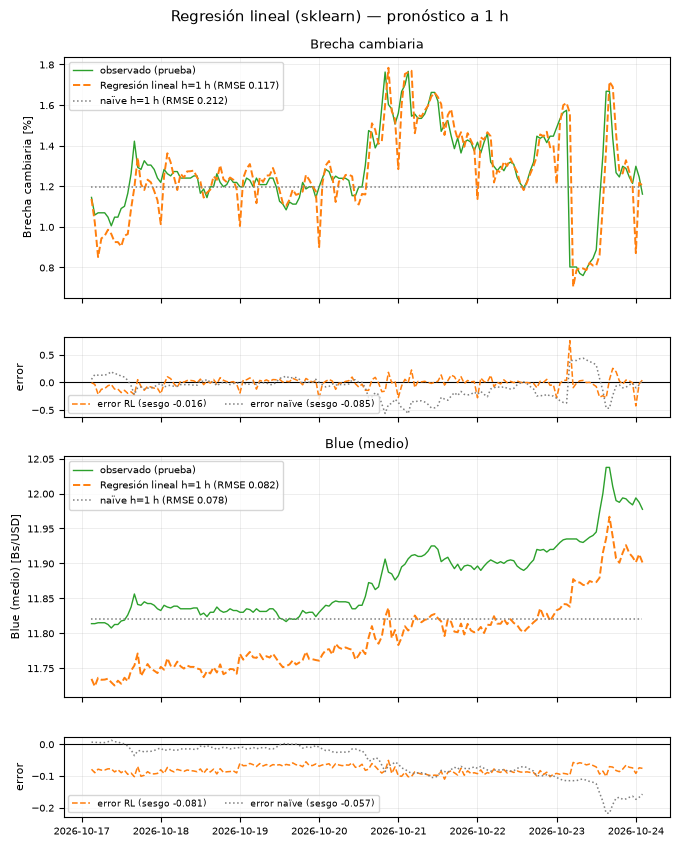

In [12]:
# test horario: observado vs RL (168 h)
from charts import figuras

fig = figuras.rl_test(te_h, pred_rl_h, naive_h,
                      etiqueta=etiqueta, etiqueta_eje=etiqueta_eje)
fig.savefig(OUT / "nb_rl_horaria_test.png", dpi=130, bbox_inches="tight")
plt.show()


### 3.3 OLS (statsmodels) — inferencia con errores HAC

El `LinearRegression` de sklearn **predice** pero no devuelve errores estándar
ni p-valores. Para la inferencia estimamos el mismo modelo con **statsmodels**
y errores **HAC de Newey–West** (24 rezagos — un ciclo diario completo),
robustos a heterocedasticidad y autocorrelación intradía. Mismos β, distinta
salida.

In [13]:
# ── datos de la inferencia HAC (mismo diseño que la regresión lineal) ───────
print("mismo diseño que la RL; cambia el estimador (statsmodels + errores HAC)")
mostrar_train(tr_h[cols_h + ["brecha_pct"]],
              "OLS-HAC — X + target brecha (train)")

mismo diseño que la RL; cambia el estimador (statsmodels + errores HAC)
[OLS-HAC — X + target brecha (train)] 4128 filas × 38 columnas | 2026-04-28 03:00 → 2026-10-17 02:00


,brecha_lag1h,brecha_lag3h,brecha_lag24h,oficial_lag1h,vol_lag1h,ret_blue_lag1h,n_docs_fx,n_docs_fx_alta,hora_1,hora_2,...,hora_21,hora_22,hora_23,dow_1,dow_2,dow_3,dow_4,dow_5,dow_6,brecha_pct
fecha,,,,,,,,,,,,,,,,,,,,,
2026-04-28 03:00:00,42.4023,42.4023,40.7381,6.91,0.1818,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,42.4023
2026-04-28 04:00:00,42.4023,42.4023,40.7381,6.91,0.1818,0.000000,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,42.3784
2026-04-28 05:00:00,42.3784,42.4023,40.7619,6.91,0.1820,-0.000163,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,42.4385
2026-04-28 06:00:00,42.4385,42.4023,40.8104,6.91,0.1819,0.000417,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,42.5470
2026-04-28 07:00:00,42.5470,42.3784,40.8589,6.91,0.1819,0.000762,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,42.6194


In [14]:
Xtr_hac = sm.add_constant(tr_h[cols_h], has_constant="add")

# descartar columnas exactamente colineales: un diseño de rango deficiente
# deja los parámetros sin identificar
def _cols_independientes(df, colnames):
    keep = []
    for c in colnames:
        trial = keep + [c]
        if np.linalg.matrix_rank(df[trial].values) == len(trial):
            keep = trial
    return keep

cols_ok = _cols_independientes(tr_h, cols_h)
print(f"predictores HAC: {len(cols_ok)} de {len(cols_h)}")

Xtr_hac = sm.add_constant(tr_h[cols_ok], has_constant="add")
ols_hac = sm.OLS(tr_h["brecha_pct"], Xtr_hac).fit(
    cov_type="HAC", cov_kwds={"maxlags": 24})

tabla_hac = ols_hac.summary2().tables[1].rename(columns={
    "Coef.": "coef", "Std.Err.": "ee_hac", "P>|z|": "p_valor",
    "[0.025": "ic2.5", "0.975]": "ic97.5"})
tabla_hac["significativo_5pct"] = tabla_hac["p_valor"] < 0.05
tabla_hac = tabla_hac.sort_values("p_valor")

print(f"R² in-sample: {ols_hac.rsquared:.4f} | n = {int(ols_hac.nobs)} | "
      f"errores HAC (Newey-West, 24 rezagos)")
sig = tabla_hac[tabla_hac["significativo_5pct"]]
print(f"coeficientes significativos al 5%: {list(sig.index)}\n")
display(tabla_hac[["coef", "ee_hac", "p_valor", "ic2.5", "ic97.5",
                   "significativo_5pct"]].round(4))

predictores HAC: 37 de 37
R² in-sample: 0.9987 | n = 4128 | errores HAC (Newey-West, 24 rezagos)
coeficientes significativos al 5%: ['brecha_lag1h', 'oficial_lag1h']



,coef,ee_hac,p_valor,ic2.5,ic97.5,significativo_5pct
brecha_lag1h,0.9899,0.0064,0.0000,0.9773,1.0024,True
oficial_lag1h,-0.0263,0.0098,0.0075,-0.0456,-0.0070,True
brecha_lag24h,0.0052,0.0034,0.1218,-0.0014,0.0118,False
dow_5,-0.1299,0.0843,0.1231,-0.2951,0.0352,False
dow_3,-0.0221,0.0166,0.1822,-0.0546,0.0104,False
dow_4,-0.0189,0.0144,0.1890,-0.0471,0.0093,False
hora_2,0.3030,0.2487,0.2232,-0.1846,0.7905,False
dow_1,-0.0241,0.0211,0.2541,-0.0655,0.0173,False
hora_3,0.2826,0.2535,0.2650,-0.2143,0.7794,False
hora_16,0.2742,0.2499,0.2725,-0.2155,0.7639,False


## 4. ARIMA — statsmodels (univariado, frecuencia horaria)

Sobre la grilla horaria: `d` lo fija ADF (nivel vs primera diferencia), el
orden (p,d,q) sale de un **grid search por AIC** (p,q ≤ 2, con y sin deriva) sobre
las últimas ~90 días de entrenamiento — se acota para controlar el costo.
Pronóstico de 168 h con IC95.

### Cómo leer la tabla de parámetros

| Columna | Qué es |
|---|---|
| `β` | coeficiente estimado: cuánto pesa cada rezago en la dinámica (sobre las primeras diferencias, porque `d=1`) |
| `ee` | **error estándar**: cuánto variaría `β` si se repitiera el muestreo. Es su precisión; `β ± 1,96·ee` da el IC95 |
| `z` | `β / ee`: cuántos errores estándar se aparta el coeficiente de cero |
| `p` | probabilidad de observar un `|z|` igual o mayor **si el efecto verdadero fuera nulo** |
| `ic2.5` / `ic97.5` | intervalo de confianza al 95 %: valores de `β` compatibles con los datos |

Regla de decisión al 5 %: si `|z| > 1,96` (equivalentemente `p < 0,05`), se
rechaza que el coeficiente sea cero. Ojo: `sigma2` es la **varianza residual**,
no un efecto — su p-valor es significativo por construcción y no aporta
evidencia.

In [15]:
# ── datos con los que se entrena el ARIMA (univariado, ~90 días) ────────────
VENTANA_H = 90 * 24
for _col in ["blue_mid", "brecha_pct"]:
    _serie = hor[_col].asfreq("h").dropna()
    _ytr = _serie.iloc[-(VENTANA_H + H_TEST):-H_TEST]
    mostrar_train(_ytr.to_frame("valor"), f"ARIMA — {_col} (train)", target="valor")

[ARIMA — blue_mid (train)] 2160 filas × 1 columnas | 2026-07-19 03:00 → 2026-10-17 02:00
  target valor: media=11.770 | sd=0.375 | min=10.485 | max=12.544


,valor
fecha,
2026-07-19 03:00:00,10.7650
2026-07-19 04:00:00,10.7638
2026-07-19 05:00:00,10.7600
2026-07-19 06:00:00,10.7562
2026-07-19 07:00:00,10.7475


[ARIMA — brecha_pct (train)] 2160 filas × 1 columnas | 2026-07-19 03:00 → 2026-10-17 02:00
  target valor: media=0.520 | sd=3.514 | min=-6.672 | max=20.105


,valor
fecha,
2026-07-19 03:00:00,-0.7834
2026-07-19 04:00:00,-0.7949
2026-07-19 05:00:00,-0.8295
2026-07-19 06:00:00,-0.8641
2026-07-19 07:00:00,-0.9447


In [16]:
# ARIMA horario: grid search reducido y ventana de ~90 días para acotar el costo
VENTANA_H = 90 * 24


def run_arima_h(serie_y, nombre, max_pq=2):
    y = serie_y.asfreq("h").dropna()
    y_tr = y.iloc[-(VENTANA_H + H_TEST):-H_TEST]
    y_te = y.iloc[-H_TEST:]

    adf_n = adfuller(y_tr)[1]
    adf_d = adfuller(y_tr.diff().dropna())[1]
    print(f"[{nombre}] ADF nivel p={adf_n:.4f} | diff(1) p={adf_d:.4f}")

    mejores = []
    # grid search sobre (p,d,q)
    for p, d, q in product(range(max_pq + 1), range(2), range(max_pq + 1)):
        if p == 0 and q == 0:
            continue
        for trend in (["n", "c"] if d >= 1 else ["c"]):
            try:
                fit = ARIMA(y_tr, order=(p, d, q), trend=trend).fit()
                mejores.append((fit.aic, p, d, q, trend))
            except Exception:
                continue
    aic, bp, bd, bq, bt = min(mejores)
    print(f"[{nombre}] ARIMA({bp},{bd},{bq}) trend={bt!r} AIC={aic:.1f}")

    mod = ARIMA(y_tr, order=(bp, bd, bq), trend=bt).fit()
    fc = mod.get_forecast(steps=H_TEST)
    pred = pd.Series(fc.predicted_mean.values, index=y_te.index)
    ci = fc.conf_int(alpha=0.05)
    naive = naive_ultimo(y_tr, H_TEST, y_te.index)
    metrica = evaluar(f"ARIMA({bp},{bd},{bq}) ({nombre})", y_te, pred, naive)
    naive_row = evaluar(f"naïve ({nombre})", y_te, naive, naive)
    return pred, y_te, naive, ci, metrica, naive_row, mod


pred_ar_h, filas_ar_h, filas_naive_ar, modelos_ar_h = {}, [], [], {}
for col, nombre in [("blue_mid", "blue_mid"), ("brecha_pct", "brecha_pct")]:
    pred, real, naive, ci, metrica, naive_row, mod_h = run_arima_h(hor[col], nombre)
    modelos_ar_h[nombre] = mod_h
    pred_ar_h[nombre] = (pred, real, naive, ci)
    filas_ar_h.append(metrica)
    filas_naive_ar.append(naive_row)

display(pd.DataFrame(filas_ar_h).set_index("modelo"))

[blue_mid] ADF nivel p=0.0008 | diff(1) p=0.0000


[blue_mid] ARIMA(2,1,1) trend='n' AIC=-9305.0


[brecha_pct] ADF nivel p=0.0306 | diff(1) p=0.0000


[brecha_pct] ARIMA(2,1,2) trend='n' AIC=2926.5


,n_test,rmse,mae,rmse_naive,mae_naive,mejora_rmse_pct,mejora_mae_pct
modelo,,,,,,,
"ARIMA(2,1,1) (blue_mid)",168,0.0775,0.0574,0.0776,0.0575,0.03,0.04
"ARIMA(2,1,2) (brecha_pct)",168,0.2172,0.1616,0.2122,0.1551,-2.37,-4.21


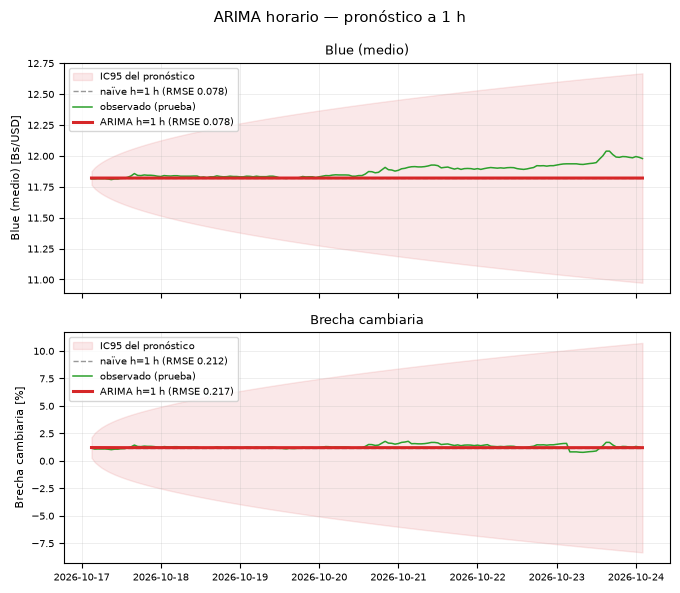

In [17]:
# test horario: observado vs ARIMA con IC95 (168 h)
from charts import figuras

fig = figuras.arima_test(pred_ar_h, etiqueta=etiqueta, etiqueta_eje=etiqueta_eje)
fig.savefig(OUT / "nb_arima_horaria_test.png", dpi=130, bbox_inches="tight")
plt.show()


In [18]:
# tabla de parámetros ARIMA horarios: β, error estándar (ee), z, p e IC95
_tablas = []
for nombre, mod_h in modelos_ar_h.items():
    ci = mod_h.conf_int()
    t = pd.DataFrame({
        "beta": mod_h.params.round(4),
        "ee": mod_h.bse.round(4),
        "z": mod_h.tvalues.round(2),
        "p": mod_h.pvalues,
        "ic2.5": ci.iloc[:, 0].round(4),
        "ic97.5": ci.iloc[:, 1].round(4),
    })
    t.insert(0, "serie", nombre)
    _tablas.append(t.reset_index().rename(columns={"index": "parametro"}))

tab_arima_params = pd.concat(_tablas, ignore_index=True)
tab_arima_params["significativo_5pct"] = tab_arima_params["p"] < 0.05
display(tab_arima_params.round({"p": 4}))
print("Parámetros significativos al 5% (sin contar sigma2):")
for nombre, g in tab_arima_params.groupby("serie"):
    sig = [p for p in g.loc[g.significativo_5pct, "parametro"] if p != "sigma2"]
    print(f"  {nombre}: {sig}")


,parametro,serie,beta,ee,z,p,ic2.5,ic97.5,significativo_5pct
0,ar.L1,blue_mid,-0.3504,0.1236,-2.83,0.0046,-0.5926,-0.1081,True
1,ar.L2,blue_mid,0.0431,0.0292,1.48,0.1393,-0.0140,0.1003,False
2,ma.L1,blue_mid,0.5579,0.1226,4.55,0.0000,0.3175,0.7983,True
3,sigma2,blue_mid,0.0008,0.0000,125.39,0.0000,0.0008,0.0008,True
4,ar.L1,brecha_pct,0.0677,0.0965,0.70,0.4831,-0.1215,0.2568,False
5,ar.L2,brecha_pct,0.6443,0.0728,8.85,0.0000,0.5016,0.7870,True
6,ma.L1,brecha_pct,-0.0446,0.0876,-0.51,0.6110,-0.2163,0.1271,False
7,ma.L2,brecha_pct,-0.7310,0.0641,-11.40,0.0000,-0.8567,-0.6053,True
8,sigma2,brecha_pct,0.2260,0.0012,189.60,0.0000,0.2237,0.2284,True


Parámetros significativos al 5% (sin contar sigma2):
  blue_mid: ['ar.L1', 'ma.L1']
  brecha_pct: ['ar.L2', 'ma.L2']


## 5. Comparación final (frecuencia horaria)

Regresión lineal vs ARIMA sobre las 168 h de hold-out, mismo target y misma
granularidad. Ordenado por RMSE; `mejor_rank` = 1 es el mejor modelo por
target. El OLS-HAC (sección 3.3) comparte β con la regresión lineal: aporta
inferencia, no predicciones nuevas.

In [19]:
# los competidores horarios + el baseline naïve, mismo corte de 168 h
# (OLS-HAC comparte β con la RL: solo agrega inferencia, no predicciones nuevas)
filas = filas_rl_h + filas_ar_h + filas_naive_h
comp = pd.DataFrame(filas).drop_duplicates(subset="modelo", keep="first") \
    .set_index("modelo").sort_values("rmse")
comp["mejor_rank"] = range(1, len(comp) + 1)
display(comp[["mejor_rank", "n_test", "rmse", "mae", "rmse_naive",
              "mejora_rmse_pct"]].round(4))

,mejor_rank,n_test,rmse,mae,rmse_naive,mejora_rmse_pct
modelo,,,,,,
"ARIMA(2,1,1) (blue_mid)",1,168,0.0775,0.0574,0.0776,0.03
naïve (blue_mid),2,168,0.0776,0.0575,0.0776,0.00
Regresión lineal (blue_mid),3,168,0.0819,0.0809,0.0776,-5.63
Regresión lineal (brecha_pct),4,168,0.1175,0.0730,0.2122,44.64
naïve (brecha_pct),5,168,0.2122,0.1551,0.2122,0.00
"ARIMA(2,1,2) (brecha_pct)",6,168,0.2172,0.1616,0.2122,-2.37


## 5d. ¿Acierta la dirección? (sube / baja a 1 hora)

**No se entrena ningún modelo nuevo.** Se reutilizan las predicciones de las
secciones 3 y 4 y se comparan con la realidad **hora a hora** en la última
semana (168 h):

- **cambio real:** `y(t) − y(t−1)` → sube si es positivo, baja si es negativo.
- **cambio predicho:** `ŷ(t) − y(t−1)` → el modelo pronostica la **hora
  siguiente** y se compara contra el último valor **real** conocido.
- **acierto (match):** ambos suben o ambos bajan.

|  | pred sube | pred baja |
|---|---:|---:|
| **real sube** | acierto | fallo |
| **real baja** | fallo | acierto |

Se excluyen las horas sin cambio (`= 0`) en la realidad o en la predicción, y
se informa `n` efectivo. Como las clases están casi balanceadas (~52 % sube),
una accuracy de 0,50 equivale a adivinar.

La única métrica de la tabla es **accuracy** = aciertos / n: la fracción
global de horas con dirección correcta. Se lee junto a la matriz de
confusión (figuras de abajo): con las celdas sube/baja a la vista no se
puede "colar" un modelo que acierte solo la clase mayoritaria — ese es
justo el caso de RL-nivel en `blue_mid` (accuracy 0,493, casi siempre
pronostica "baja" por su sesgo de nivel descrito arriba).


In [20]:
# ── ARIMA 1-paso-adelante (rolling), comparación justa de dirección ─────────
def arima_un_paso(y, nombre, max_pq=2, ventana_h=90 * 24):
    y_tr = y.iloc[-(ventana_h + H_TEST):-H_TEST]
    y_te = y.iloc[-H_TEST:]
    mejores = []
    for p, d, q in product(range(max_pq + 1), range(2), range(max_pq + 1)):
        if p == 0 and q == 0:
            continue
        for trend in (["n", "c"] if d >= 1 else ["c"]):
            try:
                mejores.append((ARIMA(y_tr, order=(p, d, q), trend=trend)
                                .fit().aic, p, d, q, trend))
            except Exception:
                continue
    _, bp, bd, bq, bt = min(mejores)
    res = ARIMA(y_tr, order=(bp, bd, bq), trend=bt).fit()
    preds = []
    for t in range(len(y_te)):
        preds.append(res.get_forecast(steps=1).predicted_mean.iloc[0])
        res = res.append(y_te.iloc[[t]], refit=False)   # 1 paso, sin re-estimar
    print(f"[{nombre}] ARIMA({bp},{bd},{bq}) 1-paso: {len(preds)} pronósticos")
    return pd.Series(preds, index=y_te.index)


pred_ar_1 = {t: arima_un_paso(hor[t], t) for t in ["blue_mid", "brecha_pct"]}


# ── dirección real y predicha (Δ contra el último valor REAL conocido) ──────
def valor_previo(target):
    """Serie con el último valor de train + el test, para Δ(t)=y(t)−y(t−1)."""
    return pd.concat([tr_h[target].iloc[[-1]], te_h[target]])


def a_signo(x, eps=0.0):
    return pd.Series(np.select([x > eps, x < -eps], [1, -1], 0), index=x.index)


filas_dir = []
for target in ["blue_mid", "brecha_pct"]:
    niveles = valor_previo(target)
    prev_actual = niveles.shift(1).iloc[1:]              # y(t−1) de cada hora del test
    real_dir = a_signo((niveles - niveles.shift(1)).iloc[1:])

    # cada modelo aporta DIRECCIÓN predicha: signo(ŷ(t) − y(t−1))
    direcciones = {
        "Regresión lineal":
            a_signo(pred_rl_h[target].reindex(prev_actual.index) - prev_actual),
        "ARIMA (1 paso)":
            a_signo(pred_ar_1[target].reindex(prev_actual.index) - prev_actual),
    }
    # variante trayectoria: signo de la serie predicha contra sí misma
    preds_nivel = {
        "Regresión lineal": pred_rl_h[target],
        "ARIMA (1 paso)": pred_ar_1[target],
    }

    for nombre, pred_dir in direcciones.items():
        # --- modo CAMBIO_ESPERADO: Δ respecto del último valor real
        ok = (real_dir != 0) & pred_dir.notna() & (pred_dir != 0)
        y, p = real_dir[ok].astype(int), pred_dir[ok].astype(int)
        if len(y):
            cm = confusion_matrix(y, p, labels=[1, -1])
            filas_dir.append({
                "target": target, "modelo": nombre, "modo": "cambio_esperado", "n": len(y),
                "aciertos": int(np.trace(cm)),
                "accuracy": round(accuracy_score(y, p), 3),
                "cm": cm,
            })

        # --- modo TRAYECTORIA: signo(ŷ(t) − ŷ(t−1))
        if nombre in preds_nivel:
            pred_serie = preds_nivel[nombre].reindex(prev_actual.index)
            dir_tray = a_signo(pred_serie - pred_serie.shift(1))
            ok2 = (real_dir != 0) & dir_tray.notna() & (dir_tray != 0)
            y2, p2 = real_dir[ok2].astype(int), dir_tray[ok2].astype(int)
            if len(y2):
                cm2 = confusion_matrix(y2, p2, labels=[1, -1])
                filas_dir.append({
                    "target": target, "modelo": nombre, "modo": "trayectoria",
                    "n": len(y2), "aciertos": int(np.trace(cm2)),
                    "accuracy": round(accuracy_score(y2, p2), 3),
                    "cm": cm2,
                })

tabla_dir = pd.DataFrame(filas_dir)
# desglose de la matriz 2x2 (labels=[1, -1]: 1 = sube, -1 = baja)
tabla_dir[["tp", "fn", "fp", "tn"]] = tabla_dir["cm"].apply(
    lambda m: pd.Series({"tp": int(m[0, 0]), "fn": int(m[0, 1]),
                         "fp": int(m[1, 0]), "tn": int(m[1, 1])}))
tabla_dir = tabla_dir.drop(columns="cm")
display(tabla_dir.sort_values(["target", "modo", "accuracy"],
                              ascending=[True, True, False])
        .set_index(["target", "modo", "modelo"]))

[blue_mid] ARIMA(2,1,1) 1-paso: 168 pronósticos


[brecha_pct] ARIMA(2,1,2) 1-paso: 168 pronósticos


n  aciertos  accuracy  tp  fn  fp  tn
target     modo            modelo                                                   
blue_mid   cambio_esperado ARIMA (1 paso)    140        81     0.579  45  29  30  36
                           Regresión lineal  140        66     0.471   0  74   0  66
           trayectoria     Regresión lineal  139        83     0.597  44  30  26  39
                           ARIMA (1 paso)    139        78     0.561  44  30  31  34
brecha_pct cambio_esperado Regresión lineal  141        85     0.603  44  27  29  41
                           ARIMA (1 paso)    141        75     0.532  35  36  30  40
           trayectoria     Regresión lineal  140        81     0.579  40  31  28  41
                           ARIMA (1 paso)    140        72     0.514  38  33  35  34

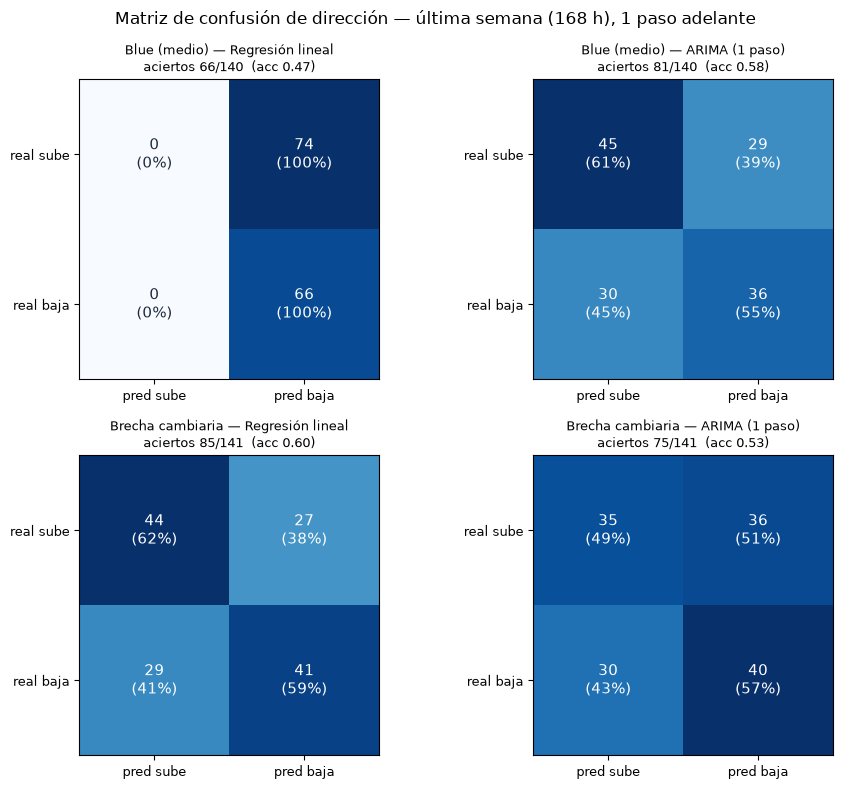

guardado: nb_confusion_direccion.png / .csv


In [21]:
# ── figura: una matriz 2×2 por target y modelo ──────────────────────────────
from charts import figuras

modelos_graf = ["Regresión lineal", "ARIMA (1 paso)"]
fig = figuras.confusion_direccion(filas_dir, etiqueta=etiqueta, modelos=modelos_graf)
fig.savefig(OUT / "nb_confusion_direccion.png", dpi=130, bbox_inches="tight")
plt.show()

# export
tabla_dir.to_csv(OUT / "nb_confusion_direccion.csv", index=False)
print("guardado: nb_confusion_direccion.png / .csv")


## 5e. Curvas ROC y AUC de la dirección

La matriz de confusión de la sección 5d evalúa una **decisión binaria**
(sube / baja) tomada en el umbral 0. La **curva ROC** evalúa el **puntaje
continuo** detrás de esa decisión: el cambio predicho
`Δ̂ = ŷ(t) − y(t−1)`.

- **Eje X** = tasa de falsos positivos (horas que bajaron y dijimos "sube").
- **Eje Y** = tasa de verdaderos positivos (horas que subieron y dijimos "sube").
- Cada punto = un umbral distinto sobre `Δ̂` (no solo 0). Al bajar el umbral,
  el modelo dice "sube" más seguido: suben ambas tasas.
- **AUC** = probabilidad de que, tomando una hora que subió y otra que bajó al
  azar, el modelo asigne un `Δ̂` mayor a la que subió. **0,5 = azar**;
  1,0 = perfecto.

Ventaja frente a la matriz: el AUC **no depende de elegir el umbral** y castiga
menos el desbalance. Se excluyen las horas sin cambio real (como en 5d) y se
comparan los modelos de las secciones 3 y 4.

In [22]:
# ── puntaje continuo por modelo: Δ̂ = ŷ(t) − y(t−1) ─────────────────────────
roc_filas, roc_datos = [], {}
for target in ["blue_mid", "brecha_pct"]:
    niveles = valor_previo(target)
    prev_actual = niveles.shift(1).iloc[1:]
    real_dir = a_signo((niveles - niveles.shift(1)).iloc[1:])

    scores = {
        "Regresión lineal":
            pred_rl_h[target].reindex(prev_actual.index) - prev_actual,
        "ARIMA (1 paso)":
            pred_ar_1[target].reindex(prev_actual.index) - prev_actual,
    }
    for nombre, score in scores.items():
        ok = (real_dir != 0) & score.notna() & (score != 0)
        y_up = (real_dir[ok] == 1).astype(int)      # 1 = subió, 0 = bajó
        s_ok = score[ok]
        if y_up.nunique() < 2:
            continue
        fpr, tpr, _ = roc_curve(y_up, s_ok)
        auc = roc_auc_score(y_up, s_ok)
        roc_datos[(target, nombre)] = (fpr, tpr, auc)
        roc_filas.append({"target": target, "modelo": nombre,
                          "n": int(len(y_up)),
                          "positivos (sube)": int(y_up.sum()),
                          "AUC": round(auc, 3)})

tabla_roc = pd.DataFrame(roc_filas).sort_values(["target", "AUC"],
                                               ascending=[True, False])
display(tabla_roc.set_index(["target", "modelo"]))

n  positivos (sube)    AUC
target     modelo                                        
blue_mid   ARIMA (1 paso)    140                74  0.564
           Regresión lineal  140                74  0.548
brecha_pct Regresión lineal  141                71  0.606
           ARIMA (1 paso)    141                71  0.563

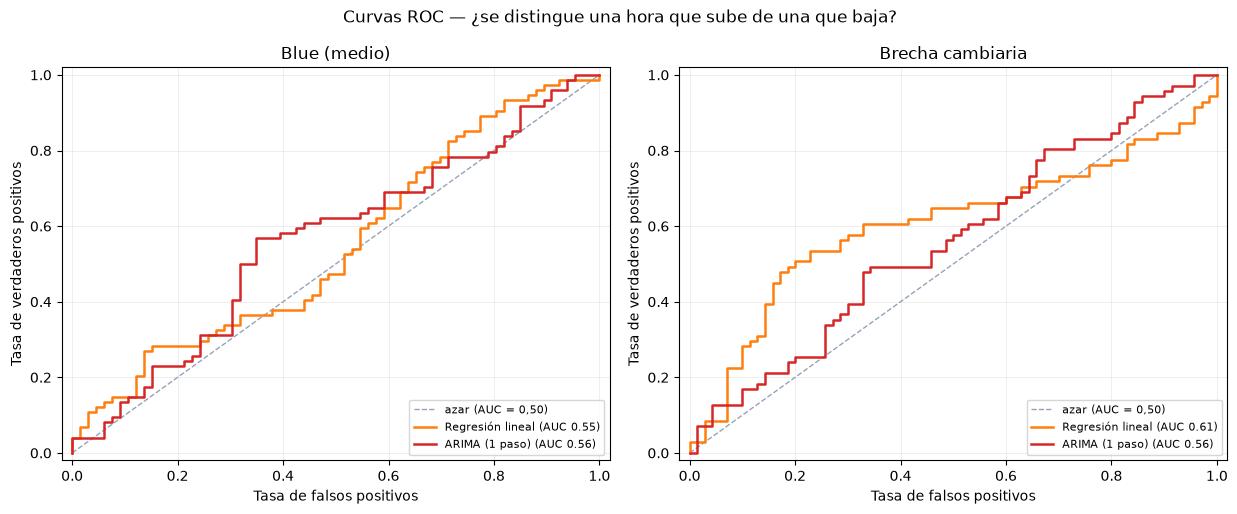

guardado: nb_roc_direccion.png / .csv


In [23]:
# ── figura: una curva ROC por target ────────────────────────────────────────
from charts import figuras

fig = figuras.roc_direccion(roc_datos, etiqueta=etiqueta)
fig.savefig(OUT / "nb_roc_direccion.png", dpi=130, bbox_inches="tight")
plt.show()

tabla_roc.to_csv(OUT / "nb_roc_direccion.csv", index=False)
print("guardado: nb_roc_direccion.png / .csv")


## 6. Parte B — Tags ↔ tipo de cambio

Event study por tag (5 h · 1 d · 3 d · 5 d) con ancla 12:00 UTC, exceso sobre
benchmark incondicional y significancia con n ≥ 5.

In [24]:
HORIZONTES = {"5 h": 5, "1 d": 24, "3 d": 72, "5 d": 120}
HORA_REF_UTC = int(os.getenv("EVENT_HORA_REF_UTC", 12))
N_MIN = 5  # mínimo de eventos para considerar un resultado

docs_f = docs[["norma_id", "fecha_edicion"]].copy()
docs_f["fecha"] = pd.to_datetime(docs_f["fecha_edicion"], errors="coerce")
eventos = (docs_f.dropna(subset=["fecha"])[["norma_id", "fecha"]]
           .merge(tags[["norma_id", "tag"]], on="norma_id")[["fecha", "tag"]]
           .drop_duplicates())

mkt_s = mkt[["fecha", "blue_mid"]].dropna().sort_values("fecha").reset_index(drop=True)


def _ancla(fecha):
    """Precio ancla: hora más cercana a HORA_REF_UTC del día de publicación."""
    dia = mkt_s[mkt_s.fecha.dt.date == fecha.date()]
    if dia.empty:
        return None
    i0 = (dia.fecha.dt.hour - HORA_REF_UTC).abs().idxmin()
    return mkt_s.at[i0, "fecha"], mkt_s.at[i0, "blue_mid"]


def _retorno(t0, p0, horas):
    """Variación % desde el ancla hasta t0 + horas (hora más cercana)."""
    i1 = (mkt_s.fecha - (t0 + pd.Timedelta(hours=horas))).abs().idxmin()
    p1 = mkt_s.at[i1, "blue_mid"]
    return (p1 - p0) / p0 * 100 if p0 and not pd.isna(p1) else np.nan


# --- retornos por fecha de publicación y horizonte ---------------------------
fechas = pd.DataFrame({"fecha": eventos.fecha.unique()})
for nombre, horas in HORIZONTES.items():
    fechas[nombre] = [
        np.nan if (a := _ancla(f)) is None else _retorno(a[0], a[1], horas)
        for f in fechas.fecha
    ]

# --- benchmark incondicional: todos los días de la grilla --------------------
incondicional = {}
for nombre, horas in HORIZONTES.items():
    vals = []
    for dia in sorted(set(mkt_s.fecha.dt.date)):
        a = _ancla(pd.Timestamp(dia))
        if a is not None:
            vals.append(_retorno(a[0], a[1], horas))
    incondicional[nombre] = float(np.nanmean(vals))
incondicional = pd.Series(incondicional)
print("benchmark incondicional (%):", incondicional.round(3).to_dict())

ev = eventos.merge(fechas, on="fecha")
con_datos = int(ev[list(HORIZONTES)].notna().any(axis=1).sum())
print(f"pares (fecha, tag) con datos de mercado: {con_datos} de {len(eventos)}")
print(f"(la grilla horaria cubre {mkt_s.fecha.dt.date.nunique()} días: "
      f"{mkt_s.fecha.min().date()} -> {mkt_s.fecha.max().date()})")

largo = (ev.melt(id_vars=["fecha", "tag"], value_vars=list(HORIZONTES),
                 var_name="horizonte", value_name="ret")
           .dropna())

g = (largo.groupby(["tag", "horizonte"])["ret"]
     .agg(n="count", media="mean", mediana="median", desv="std").reset_index())
g["ic95"] = 1.96 * g["desv"].fillna(0) / np.sqrt(g["n"])

media = g.pivot(index="tag", columns="horizonte", values="media").reindex(columns=list(HORIZONTES))
n_ev = g.pivot(index="tag", columns="horizonte", values="n").reindex(columns=list(HORIZONTES))
ic95 = g.pivot(index="tag", columns="horizonte", values="ic95").reindex(columns=list(HORIZONTES))
exceso = media - incondicional
signif = (exceso.abs() > ic95) & (n_ev >= N_MIN)

print("\n== variación media (%) ==")
display(media.round(3))
print("== exceso vs. benchmark (pp) — * significativo (|exceso|>IC95 y n>=5) ==")
display(pd.DataFrame(
    {h: [f"{v:+.3f}" + ("*" if signif.loc[t, h] else "")
         for t, v in exceso[h].items()] for h in HORIZONTES},
    index=exceso.index))
print("== nº de eventos ==")
display(n_ev.fillna(0).astype(int))

# tabla larga para reutilizar/exportar
resumen_eventos = g.merge(incondicional.rename("benchmark"), left_on="horizonte", right_index=True)
resumen_eventos["exceso"] = resumen_eventos["media"] - resumen_eventos["benchmark"]
resumen_eventos.to_csv(OUT / "nb_event_study_tag.csv", index=False)


benchmark incondicional (%): {'5 h': 0.038, '1 d': 0.121, '3 d': 0.336, '5 d': 0.541}
pares (fecha, tag) con datos de mercado: 117 de 249
(la grilla horaria cubre 181 días: 2026-04-27 -> 2026-10-24)

== variación media (%) ==


horizonte,5 h,1 d,3 d,5 d
tag,,,,
comercio_exterior,-0.053,0.343,0.508,1.326
contrataciones_estado,0.115,0.292,0.042,0.136
credito_financiero,0.192,0.664,1.060,1.322
deuda_externa,-0.204,0.053,0.188,0.870
divisas_control_cambios,-0.285,-0.311,0.054,0.953
fiscal_presupuesto,0.497,1.061,3.830,3.378
general_administrativo,0.015,0.255,1.031,1.210
impuestos,0.178,0.374,0.575,1.051
mineria_energia,0.169,0.340,0.026,0.206


== exceso vs. benchmark (pp) — * significativo (|exceso|>IC95 y n>=5) ==


,5 h,1 d,3 d,5 d
tag,,,,
comercio_exterior,-0.092,+0.222,+0.171,+0.785
contrataciones_estado,+0.077,+0.171,-0.294,-0.404
credito_financiero,+0.154,+0.544,+0.724,+0.781
deuda_externa,-0.242,-0.068,-0.148,+0.329
divisas_control_cambios,-0.323,-0.432,-0.283,+0.412
fiscal_presupuesto,+0.458,+0.940,+3.494,+2.837
general_administrativo,-0.024,+0.134,+0.695,+0.670
impuestos,+0.140,+0.253,+0.239,+0.511
mineria_energia,+0.131,+0.219,-0.310,-0.334


== nº de eventos ==


horizonte,5 h,1 d,3 d,5 d
tag,,,,
comercio_exterior,12,12,12,12
contrataciones_estado,1,1,1,1
credito_financiero,7,7,7,7
deuda_externa,6,6,6,6
divisas_control_cambios,5,5,5,5
fiscal_presupuesto,4,4,4,4
general_administrativo,42,42,42,42
impuestos,22,22,22,22
mineria_energia,18,18,18,18


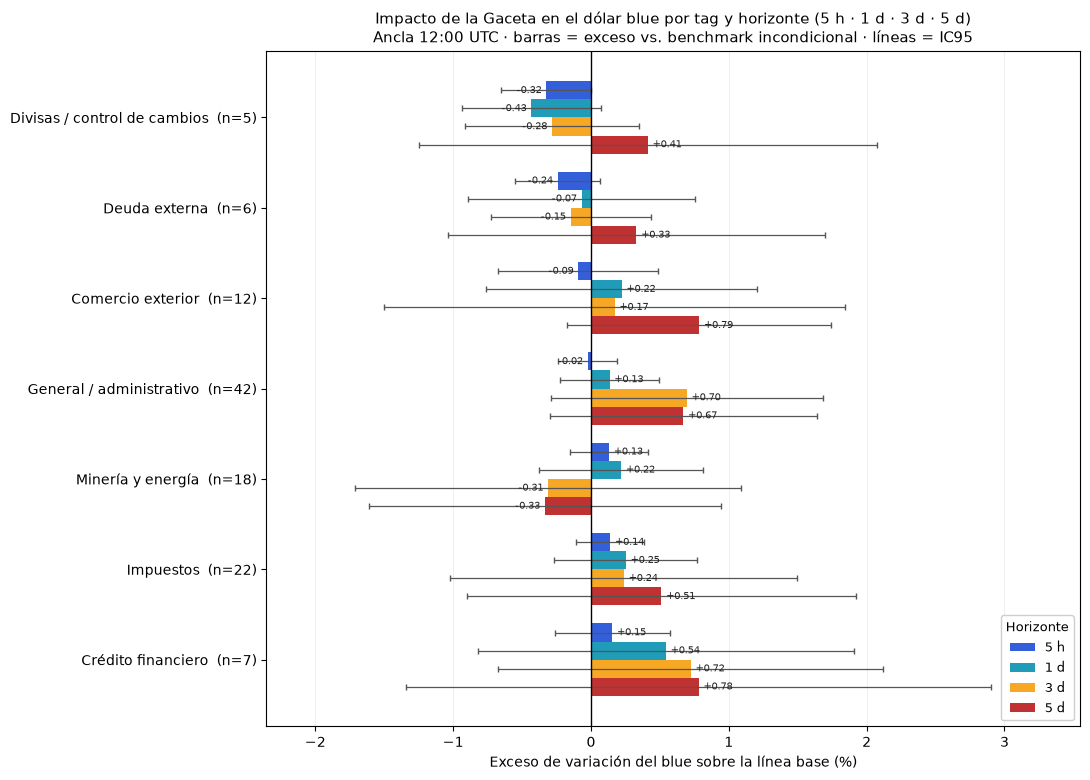

tags graficados: ['divisas_control_cambios', 'deuda_externa', 'comercio_exterior', 'general_administrativo', 'mineria_energia', 'impuestos', 'credito_financiero']


In [25]:
# Solo tags con muestra suficiente en todos los horizontes
from charts import figuras

tags_ok = [t for t in exceso.index if (n_ev.loc[t] >= N_MIN).all()]
graf = exceso.loc[tags_ok].copy()          # orden por efecto a 5 h
graf = graf.loc[graf["5 h"].sort_values().index]
err = ic95.loc[graf.index]
n_txt = {t: int(n_ev.loc[t].max()) for t in graf.index}

fig = figuras.event_study_tag(graf, err, n_txt,
                              etiqueta_tag=etiqueta_tag, hora_ref=HORA_REF_UTC)
fig.savefig(OUT / "nb_event_study_tag.png", dpi=150, bbox_inches="tight")
plt.show()
print("tags graficados:", list(graf.index))


## 7. Correlación diaria tag ↔ retorno del blue

Por día se cuenta cuántas normas de cada tag se publicaron y se cruza con el
retorno diario del blue (`ret_blue_pct`).

Se usa **Spearman** (correlación de rangos) y no Pearson: el conteo diario de
normas es una variable discreta, muy sesgada hacia cero (la mayoría de los días
no hay publicaciones de un tag), y el retorno del blue tiene valores atípicos.
Pearson mide relación *lineal* y es sensible a ambos problemas; Spearman trabaja
con los rangos, así que es robusto a la no normalidad y a los outliers, y detecta
relaciones monótonas no lineales.

Se calcula en el **mismo día** (t) y con **un día de rezago** (t+1), porque la
publicación suele surtir efecto al día siguiente. ρ ∈ [−1, 1]: cuanto más lejos
de 0, más fuerte la asociación (el signo indica la dirección).


In [26]:
tag_dia = (docs_f.dropna(subset=["fecha"])
           .merge(tags[["norma_id", "tag"]], on="norma_id")
           .groupby(["fecha", "tag"]).size().unstack(fill_value=0).sort_index())
tag_dia = tag_dia.reindex(
    pd.date_range(tag_dia.index.min(), tag_dia.index.max(), freq="D"),
    fill_value=0)

ret = serie["ret_blue_pct"].dropna()
base = pd.DataFrame(index=ret.index.intersection(tag_dia.index))
base["ret_t"] = ret.reindex(base.index)
base["ret_t1"] = ret.shift(-1).reindex(base.index)

corr = []
for tag in tag_dia.columns:
    c = tag_dia[tag].reindex(base.index)
    corr.append({
        "tag": tag,
        "dias_con_publicacion": int((c > 0).sum()),
        "spearman_t": c.corr(base["ret_t"], method="spearman"),
        "spearman_t1": c.corr(base["ret_t1"], method="spearman"),
    })
corr = pd.DataFrame(corr).set_index("tag").sort_values("spearman_t1")
display(corr.round(3))


,dias_con_publicacion,spearman_t,spearman_t1
tag,,,
divisas_control_cambios,9,-0.026,-0.099
deuda_externa,15,-0.018,-0.094
credito_financiero,15,0.031,-0.017
general_administrativo,88,0.034,0.008
comercio_exterior,24,0.023,0.014
contrataciones_estado,2,-0.059,0.020
mineria_energia,34,0.160,0.036
fiscal_presupuesto,10,0.019,0.083
impuestos,41,0.039,0.095


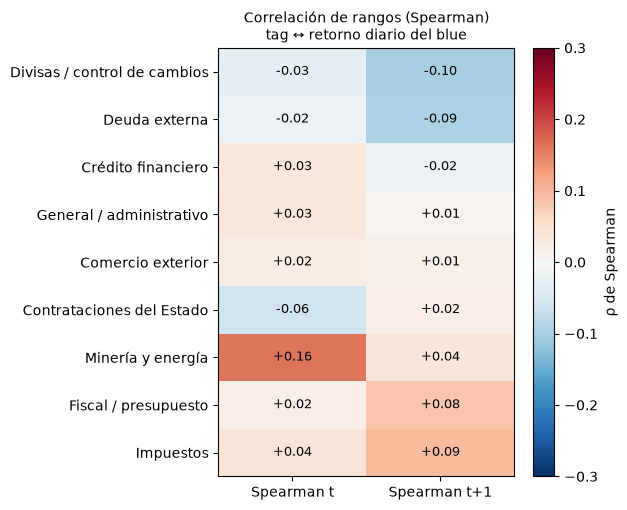

In [27]:
from charts import figuras

fig = figuras.corr_tag_heatmap(corr, etiqueta_tag=etiqueta_tag)
fig.savefig(OUT / "nb_corr_tag_heatmap.png", dpi=130, bbox_inches="tight")
plt.show()


## 8. Conclusiones

> La ventana de evaluación son **las últimas 168 h del dataset** (se imprime en
> la sección 1). Si el pipeline actualiza `market_hourly.csv`, la semana y los
> valores cambian: los números de abajo corresponden a la corrida actual.

### Objetivo 1 — nivel (RMSE sobre 168 h)

Cada modelo se compara con la línea base **de su mismo horizonte**: el ARIMA
pronostica 168 pasos desde el corte (naïve *constante*), la regresión se
actualiza hora a hora (naïve *de un paso*, repetir el valor real de la hora
anterior).

| Target | Modelo | Horizonte | RMSE | RMSE ÷ naïve |
|---|---|---:|---:|---:|
| `blue_mid` | naïve constante | 168 h | 0,0776 | 1,00 |
| `blue_mid` | ARIMA(2,1,1) | 168 h | 0,0780 | 1,00 (empata) |
| `blue_mid` | **naïve a 1 paso** | 1 h | **0,0077** | 1,00 |
| `blue_mid` | Regresión lineal | 1 h | 0,0819 | **10,6** (peor) |
| `brecha_pct` | naïve constante | 168 h | 0,2122 | 1,00 |
| `brecha_pct` | ARIMA(2,1,2) | 168 h | 0,2170 | 1,02 (peor) |
| `brecha_pct` | **naïve a 1 paso** | 1 h | **0,0910** | 1,00 |
| `brecha_pct` | Regresión lineal | 1 h | 0,1175 | **1,29** (peor) |

- **Ningún modelo baja de 1,00:** con frecuencia horaria el último valor
  contiene casi toda la información. El nivel del blue es prácticamente un
  paseo aleatorio (repetir la hora anterior deja 0,0077 Bs, 0,07 % del precio).
- **La ventaja aparente de la regresión en la brecha (+44,6 %)** era un
  artefacto: comparaba un modelo de un paso contra un pronóstico estático de
  168 h. Contra el naïve a 1 paso pierde 1,29×.
- **El ARIMA empata** en el nivel y pierde apenas 2,4 % en la brecha; su valor
  está en la banda de incertidumbre, no en el error puntual.

### Objetivo 1b — dirección (sección 5d)

| Target | Modo | Mejor modelo | accuracy |
|---|---|---|---:|
| `blue_mid` | nivel | ARIMA 1-paso | 0,579 |
| `blue_mid` | trayectoria | Regresión lineal | 0,590 |
| `brecha_pct` | nivel | **Regresión lineal** | **0,603** |
| `brecha_pct` | trayectoria | Regresión lineal | 0,579 |

La regresión lineal sobre **`blue_mid` degenera** en modo *cambio_esperado*: su sesgo
(predice por debajo del nivel real) la lleva a pronosticar "baja" casi siempre
(accuracy 0,471 ≈ la frecuencia de bajadas).

### Objetivo 1c — ROC / AUC (sección 5e)

| Target | Regresión lineal | ARIMA 1-paso |
|---|---:|---:|
| `blue_mid` | 0,561 | 0,561 |
| `brecha_pct` | **0,604** | 0,563 |

**Todas las AUC están entre 0,52 y 0,60:** la capacidad de **distinguir una hora
que sube de una que baja es débil** (0,5 = azar). La mejor señal aparece en la
brecha con la regresión lineal (0,604), coherente con que sea el único target
donde el modelo supera al naïve en nivel.

> **Estabilidad:** con n ≈ 140 horas por semana, el error estándar de la
> accuracy ronda ±8 pp. El ranking entre modelos **cambia de una semana a
> otra**, así que conviene leer estas cifras como "señal débil e inestable",
> no como una ventaja consolidada.

### Objetivo 2 — Gaceta ↔ tipo de cambio

Los tags cambiarios (`divisas_control_cambios`, `deuda_externa`) son los únicos
con exceso **negativo** a 5 h y 1 d — la dirección que predice la hipótesis —
pero **ningún tag es significativo al 95 %** en ningún horizonte con n ≥ 5.
En la inferencia HAC solo resultan significativos `brecha_lag1h` y
`oficial_lag1h`; la Gaceta no aporta.

### Limitaciones

Grilla horaria de ~6 meses (120 de 249 pares fecha-tag quedan fuera);
`contrataciones_estado` con n = 1; extracción LLM de la Gaceta solo 3 días
(canales por palabras clave, 509 normas); ventana ARIMA de ~90 días para
acotar el costo del grid search; una sola semana de test.
